# Using LSDB plot the light curve of a given diaObjectId

The lightu curve plot is inspired from this tutorial: https://docs.lsdb.io/en/latest/tutorials/pre_executed/rubin_dp2_historical_dia.html. The tutorial uses DP2 object catalog, we cannot use that.

In [1]:
! pip install lsdb hats

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 3.0 MB/s eta 0:00:00
INFO: pip is looking at multiple versions of numba to determine which version is compatible with other requirements. This could take a while.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 141.5/141.5 kB 11.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 119.3/119.3 kB 10.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 27.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 120.2/120.2 kB 9.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 48.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 102.1/102.1 kB 8.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 221.7/221.7 kB 17.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.8/3.8 MB 53.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 46.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 54.0 MB/

In [1]:
import lsdb
import pyarrow as pa
import pyarrow.compute as pc

from dask.distributed import Client

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import os
import time
import threading
import polars as pl

import astropy.units as u

from lsdb import ConeSearch


# What is the schema of the alerts archive

In [2]:
catalog = lsdb.open_catalog('https://data.lsdb.io/hats/rubin_alert_archive')

In [3]:
catalog

,ra,dec,diaSourceId,diaSource,diaObject,prvDiaForcedSources
npartitions=219,,,,,,
"Order: 1, Pixel: 16",double[pyarrow],double[pyarrow],int64[pyarrow],"nested<diaObjectId: [int64], ssObjectId: [int6...","nested<diaObjectId: [int64], nDiaSources: [int...","nested<diaForcedSourceId: [int64], visit: [int..."
...,...,...,...,...,...,...
"Order: 3, Pixel: 766",...,...,...,...,...,...
"Order: 3, Pixel: 767",...,...,...,...,...,...


In [4]:
del catalog

In [5]:
catalog = lsdb.open_catalog(
    'https://data.lsdb.io/hats/rubin_alert_archive',
    columns=[
        "diaSourceId", "diaSource", "diaObject", "prvDiaForcedSources"
    ],
)

In [6]:
catalog

,diaSourceId,diaSource,diaObject,prvDiaForcedSources,ra,dec
npartitions=219,,,,,,
"Order: 1, Pixel: 16",int64[pyarrow],"nested<diaSourceId: [int64], visit: [int64], d...","nested<diaObjectId: [int64], validityStartMjdT...","nested<diaForcedSourceId: [int64], diaObjectId...",double[pyarrow],double[pyarrow]
...,...,...,...,...,...,...
"Order: 3, Pixel: 766",...,...,...,...,...,...
"Order: 3, Pixel: 767",...,...,...,...,...,...


In [7]:
oid = 170019696266444924

## Query 1 diaObjectId

This is very slowww, I wonder if it's faster when doing large queries

In [8]:
def filter_nested(df, values):
    # .isin() is perfectly supported on nested sub-columns in nested-pandas
    mask = (df["diaSource.diaObjectId"] == values)
    return df[mask]

# Apply the function across all Dask partitions safely
filtered_catalog = catalog.map_partitions(
    filter_nested,
    values=oid,
).compute()

Computing Catalog:   0%|          | 0/438 [00:00<?, ?it/s]

In [9]:
filtered_catalog

diaSourceId  \
_healpix_29                               
2414464557774505392  170063689203843080   
2414464557774530121  170054925607239760   
...                                 ...   
2414464557798016851  170050479762964499   
2414464557798108583  170063676327329848   

                                                             diaSource  \
_healpix_29                                                              
2414464557774505392  [{diaSourceId: 170063689203843080, visit: 2026...   
2414464557774530121  [{diaSourceId: 170054925607239760, visit: 2026...   
...                                                                ...   
2414464557798016851  [{diaSourceId: 170050479762964499, visit: 2026...   
2414464557798108583  [{diaSourceId: 170063676327329848, visit: 2026...   

                                                             diaObject  \
_healpix_29                                                              
2414464557774505392  [{diaObjectId: 170019696266444924, validitySta...   
2414464557774530121  [{diaObjectId: 170019696266444924, validitySta...   
...                                                                ...   
2414464557798016851  [{diaObjectId: 170019696266444924, validitySta...   
2414464557798108583  [{diaObjectId: 170019696266444924, validitySta...   

                                                   prvDiaForcedSources  \
_healpix_29                                                              
2414464557774505392  [{diaForcedSourceId: 170028485776506894, diaOb...   
2414464557774530121  [{diaForcedSourceId: 170028485776506894, diaOb...   
...                                                                ...   
2414464557798016851  [{diaForcedSourceId: 170028485776506894, diaOb...   
2414464557798108583  [{diaForcedSourceId: 170028485776506894, diaOb...   

                            ra        dec  
_healpix_29                                
2414464557774505392  59.899067 -50.459736  
2414464557774530121  59.899066 -50.459719  
...                        ...        ...  
2414464557798016851  59.899076 -50.459616  
2414464557798108583  59.899054 -50.459585  

[295 rows x 6 columns]

In [10]:
preview = filtered_catalog.head(4)
preview

diaSourceId  \
_healpix_29                               
2414464557774505392  170063689203843080   
2414464557774530121  170054925607239760   
2414464557774674709  170032883969294360   
2414464557774681507  170059274519576593   

                                                             diaSource  \
_healpix_29                                                              
2414464557774505392  [{diaSourceId: 170063689203843080, visit: 2026...   
2414464557774530121  [{diaSourceId: 170054925607239760, visit: 2026...   
2414464557774674709  [{diaSourceId: 170032883969294360, visit: 2026...   
2414464557774681507  [{diaSourceId: 170059274519576593, visit: 2026...   

                                                             diaObject  \
_healpix_29                                                              
2414464557774505392  [{diaObjectId: 170019696266444924, validitySta...   
2414464557774530121  [{diaObjectId: 170019696266444924, validitySta...   
2414464557774674709  [{diaObjectId: 170019696266444924, validitySta...   
2414464557774681507  [{diaObjectId: 170019696266444924, validitySta...   

                                                   prvDiaForcedSources  \
_healpix_29                                                              
2414464557774505392  [{diaForcedSourceId: 170028485776506894, diaOb...   
2414464557774530121  [{diaForcedSourceId: 170028485776506894, diaOb...   
2414464557774674709  [{diaForcedSourceId: 170028485776506894, diaOb...   
2414464557774681507  [{diaForcedSourceId: 170028485776506894, diaOb...   

                            ra        dec  
_healpix_29                                
2414464557774505392  59.899067 -50.459736  
2414464557774530121  59.899066 -50.459719  
2414464557774674709  59.899099 -50.459718  
2414464557774681507  59.899097 -50.459713

# Plot the detection light curve

In [11]:
def add_prv_mag(flux, flux_err):
    """Convert flux (nJy) to AB magnitude (asymmetric error from flux ± fluxErr)"""
    flux = np.asarray(flux, dtype="float64")
    flux_err = np.asarray(flux_err, dtype="float64")
    mag = u.nJy.to(u.ABmag, flux)
    upper = u.nJy.to(u.ABmag, flux + flux_err)
    lower = u.nJy.to(u.ABmag, flux - flux_err)
    mag_err = -(upper - lower) / 2
    return {"diaSource.psfMag": mag, "diaSource.psfMagErr": mag_err}


def append_prv_mag(nf):
    """Append psfMag/psfMagErr onto the nested prvDiaForcedSources column"""
    return nf.map_rows(
        add_prv_mag,
        columns=["diaSource.psfFlux", "diaSource.psfFluxErr"],
        append_columns=True,
        row_container="args",
    )


preview = append_prv_mag(filtered_catalog)

In [12]:
def combined_light_curve(match, i):
    """Concatenate both nested light curves, keeping band, time, and magnitude"""
    prv_dia_forced_source = match["diaSource"].iloc[i]
    # forced_source = match["diaObjectForcedSource"].iloc[i]
    return pd.concat([prv_dia_forced_source], ignore_index=True)

In [13]:
! pip install -qq lsdb-rubin

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 20.8/20.8 MB 48.4 MB/s eta 0:00:00


In [14]:
preview["diaSource"].iloc[0]

,diaSourceId,visit,detector,diaObjectId,ssObjectId,parentDiaSourceId,midpointMjdTai,ra,raErr,dec,...,pixelFlags_suspectCenter,pixelFlags_streak,pixelFlags_streakCenter,pixelFlags_injected,pixelFlags_injectedCenter,pixelFlags_injected_template,pixelFlags_injected_templateCenter,glint_trail,psfMag,psfMagErr
0,170063689203843080,2026022600199,6,170019696266444924,0,0,61098.102265,59.899067,0.000045,-50.459736,...,False,False,False,False,False,False,False,False,22.768894,0.118408


In [15]:
oid

170019696266444924

In [16]:
from lsdb_rubin.plot_light_curve import plot_light_curve

filter_colors = {
    "u": "#1600ea",
    "g": "#49be61",
    "r": "#c61c00",
    "i": "#ffc200",
    "z": "#f341a2",
    "y": "#5d0000",
}

In [18]:
df_all = pd.DataFrame()
for i in range(len(filtered_catalog)):
  dfi = combined_light_curve(preview, i)
  df_all =  pd.concat([df_all, dfi], ignore_index=True)

In [19]:
df_all

,diaSourceId,visit,detector,diaObjectId,ssObjectId,parentDiaSourceId,midpointMjdTai,ra,raErr,dec,...,pixelFlags_suspectCenter,pixelFlags_streak,pixelFlags_streakCenter,pixelFlags_injected,pixelFlags_injectedCenter,pixelFlags_injected_template,pixelFlags_injected_templateCenter,glint_trail,psfMag,psfMagErr
0,170063689203843080,2026022600199,6,170019696266444924,0,0,61098.102265,59.899067,0.000045,-50.459736,...,False,False,False,False,False,False,False,False,22.768894,0.118408
1,170054925607239760,2026022400441,36,170019696266444924,0,0,61096.065275,59.899066,0.000023,-50.459719,...,False,False,False,False,False,False,False,False,23.555339,0.137603
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
293,170050479762964499,2026022300085,5,170019696266444924,0,0,61095.068261,59.899076,0.000021,-50.459616,...,False,False,False,False,False,False,False,False,22.387312,0.108034
294,170063676327329848,2026022600103,22,170019696266444924,0,0,61098.056431,59.899054,0.000043,-50.459585,...,False,False,False,False,False,False,False,False,23.418184,0.184220


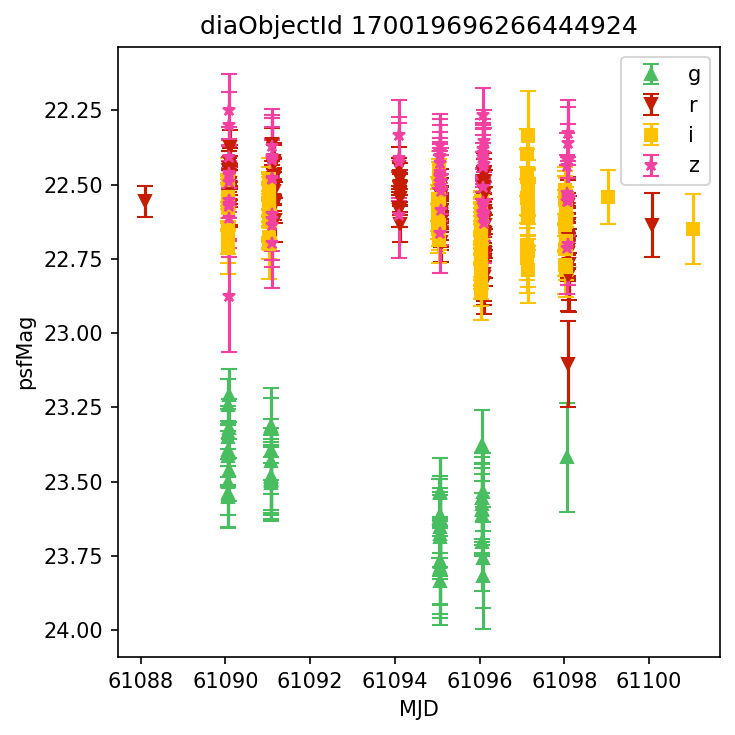

In [20]:


fig, ax = plt.subplots(1,1, figsize=(5, 5), dpi=150)

plt.sca(ax)
plot_light_curve(
    df_all,
    mag_field="psfMag",
    title=f"diaObjectId {preview['diaObject.diaObjectId'].iloc[i]}",
    filter_colors=filter_colors,
    plot_kwargs={"capsize": 4},
)

fig.tight_layout()
plt.show()

# Plot the forced photometry light curve

In [21]:
def add_prv_mag(flux, flux_err):
    """Convert flux (nJy) to AB magnitude (asymmetric error from flux ± fluxErr)"""
    flux = np.asarray(flux, dtype="float64")
    flux_err = np.asarray(flux_err, dtype="float64")
    mag = u.nJy.to(u.ABmag, flux)
    upper = u.nJy.to(u.ABmag, flux + flux_err)
    lower = u.nJy.to(u.ABmag, flux - flux_err)
    mag_err = -(upper - lower) / 2
    return {"prvDiaForcedSources.psfMag": mag, "prvDiaForcedSources.psfMagErr": mag_err}


def append_prv_mag(nf):
    """Append psfMag/psfMagErr onto the nested prvDiaForcedSources column"""
    return nf.map_rows(
        add_prv_mag,
        columns=["prvDiaForcedSources.psfFlux", "prvDiaForcedSources.psfFluxErr"],
        append_columns=True,
        row_container="args",
    )


preview_fp = append_prv_mag(filtered_catalog)

/usr/local/lib/python3.13/dist-packages/astropy/units/function/logarithmic.py:67: RuntimeWarning: invalid value encountered in log10
  return dex.to(self._function_unit, np.log10(x))


In [24]:
preview_fp['prvDiaForcedSources'].iloc[0]

,diaForcedSourceId,diaObjectId,ra,dec,visit,detector,psfFlux,psfFluxErr,midpointMjdTai,scienceFlux,scienceFluxErr,band,timeProcessedMjdTai,timeWithdrawnMjdTai,psfMag,psfMagErr
0,170028485776506894,170019696266444924,59.899053,-50.459672,2026021800057,13,3225.742676,241.478867,61090.048021,15085.744141,237.166916,i,61090.050034,NaN,22.628426,0.081430
1,170028486042320913,170019696266444924,59.899035,-50.459668,2026021800059,8,3494.177490,249.491180,61090.053112,16106.106445,244.578888,i,61090.055393,NaN,22.541638,0.077656
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
359,170063688400109654,170019696266444924,59.899043,-50.459669,2026022600193,9,3070.272705,299.001160,61098.099580,10374.329102,295.697083,r,61098.101464,NaN,22.682058,0.106072
360,170063689203843134,170019696266444924,59.899043,-50.459670,2026022600199,6,2792.645508,315.569611,61098.102265,10726.333984,311.964783,r,61098.104156,NaN,22.784960,0.123215


In [27]:
def combined_light_curve(match, i):
    """Concatenate both nested light curves, keeping band, time, and magnitude"""
    # prv_dia_forced_source = match["diaSource"].iloc[i]
    forced_source = match["prvDiaForcedSources"].iloc[i]
    return pd.concat([forced_source], ignore_index=True)

In [33]:
df_all_fp = pd.DataFrame()
for i in range(len(filtered_catalog)):
  dfi = combined_light_curve(preview_fp, i)
  df_all_fp =  pd.concat([df_all_fp, dfi], ignore_index=True)

In [34]:
df_all_fp

,diaForcedSourceId,diaObjectId,ra,dec,visit,detector,psfFlux,psfFluxErr,midpointMjdTai,scienceFlux,scienceFluxErr,band,timeProcessedMjdTai,timeWithdrawnMjdTai,psfMag,psfMagErr
0,170028485776506894,170019696266444924,59.899053,-50.459672,2026021800057,13,3225.742676,241.478867,61090.048021,15085.744141,237.166916,i,61090.050034,NaN,22.628426,0.08143
1,170028486042320913,170019696266444924,59.899035,-50.459668,2026021800059,8,3494.17749,249.49118,61090.053112,16106.106445,244.578888,i,61090.055393,NaN,22.541638,0.077656
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48540,170063675514683405,170019696266444924,59.899042,-50.45967,2026022600097,8,1515.447998,263.483124,61098.053831,4085.752686,259.611847,g,61098.055577,NaN,23.448647,0.190709
48541,170063676327329940,170019696266444924,59.899042,-50.45967,2026022600103,22,1367.176147,266.607208,61098.056431,3579.054932,263.101135,g,61098.058185,NaN,23.560439,0.214472


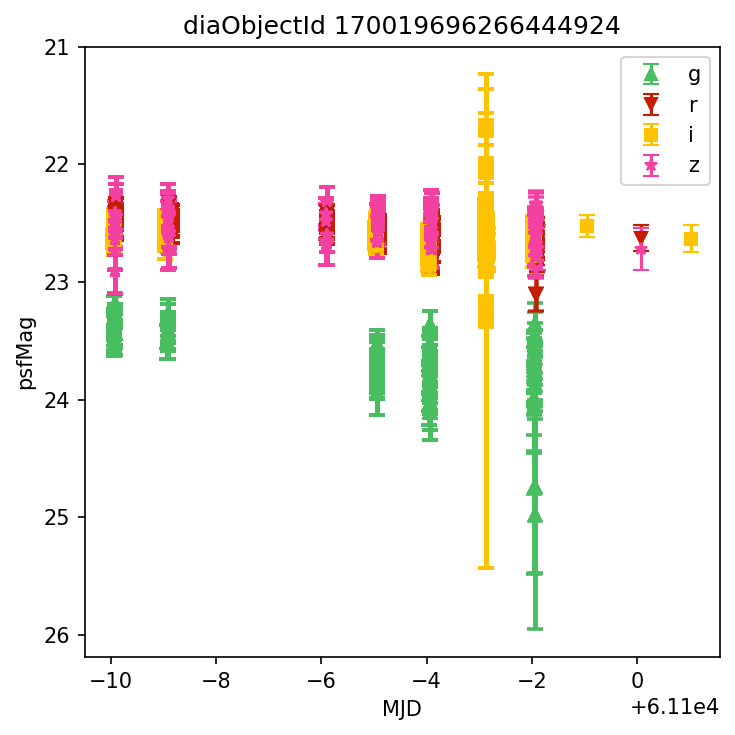

In [36]:
fig, ax = plt.subplots(1,1, figsize=(5, 5), dpi=150)

plt.sca(ax)
plot_light_curve(
    df_all_fp,
    mag_field="psfMag",
    title=f"diaObjectId {preview['prvDiaForcedSources.diaObjectId'].iloc[i]}",
    filter_colors=filter_colors,
    plot_kwargs={"capsize": 4},
)

fig.tight_layout()
plt.show()